# Actuarial Baseline Models (GLM Framework)

Classical Generalized Linear Model benchmarks: Poisson Frequency with log(Exposure) offset, Gamma Severity, Two-Part Pure Premium, and Direct Tweedie GLM.

> Run notebooks in order 01 → 06: later notebooks load artifacts saved by earlier ones.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

import statsmodels.api as sm
import statsmodels.formula.api as smf


class FrequencyPoissonGLM:

    def __init__(self, formula: str = None, target_col: str = "AttritionalClaimNb_Capped"):
        if formula is None:
            self.formula = (
                "AttritionalClaimNb_Capped ~ bs(DrivAge, df=4) + bs(VehAge, df=3) + VehPower + "
                "BonusMalus + LogDensity + C(Area) + C(VehGas) + C(VehBrand) + C(Region)"
            )
        else:
            self.formula = formula
        self.target_col = target_col
        self.model = None
        self.results = None

    def fit(self, df: pd.DataFrame, offset_col: str = "LogExposure"):
        # Fall back to ClaimNb if capped column is missing (e.g. minimal test frames)
        formula = self.formula
        if self.target_col not in df.columns and "ClaimNb" in df.columns:
            formula = formula.replace(self.target_col, "ClaimNb", 1)
        self.model = smf.glm(
            formula=formula,
            data=df,
            family=sm.families.Poisson(link=sm.families.links.Log()),
            offset=df[offset_col]
        )
        self.results = self.model.fit()
        return self

    def predict(self, df: pd.DataFrame, offset_col: str = None) -> np.ndarray:
        if offset_col is not None:
            return self.results.predict(df, offset=df[offset_col])
        # Return annualized frequency (exposure = 1.0, offset = 0.0)
        zero_offset = np.zeros(len(df))
        return self.results.predict(df, offset=zero_offset)


class SeverityGammaGLM:

    def __init__(self, formula: str = None, large_loss_threshold: float = 100_000.0):
        if formula is None:
            self.formula = (
                "AvgClaimSeverity ~ DrivAge + VehAge + VehPower + "
                "BonusMalus + LogDensity + C(Area) + C(VehGas)"
            )
        else:
            self.formula = formula
        self.large_loss_threshold = large_loss_threshold
        self.model = None
        self.results = None

    def fit(self, df: pd.DataFrame):
        claims_df = df[
            (df["HasAttritionalLoss"] == 1) & 
            (df["AvgClaimSeverity"] > 0) & 
            (df["AvgClaimSeverity"] < self.large_loss_threshold) &
            (df["AttritionalClaimAmount"] > 0)
        ].copy()
        
        weights = claims_df["AttritionalSevRecordCount"].clip(lower=1)
        self.model = smf.glm(
            formula=self.formula,
            data=claims_df,
            family=sm.families.Gamma(link=sm.families.links.Log()),
            var_weights=weights
        )
        self.results = self.model.fit()
        return self

    def predict(self, df: pd.DataFrame) -> np.ndarray:
        return self.results.predict(df)


class TweedieGLM:

    def __init__(self, formula: str = None, var_power: float = 1.5):
        if formula is None:
            self.formula = (
                "PurePremium ~ DrivAge + VehAge + VehPower + "
                "BonusMalus + LogDensity + C(Area) + C(VehGas)"
            )
        else:
            self.formula = formula
        self.var_power = var_power
        self.model = None
        self.results = None

    def fit(self, df: pd.DataFrame, exposure_col: str = "Exposure_Capped"):
        weights = df[exposure_col].clip(lower=0.001)
        self.model = smf.glm(
            formula=self.formula,
            data=df,
            family=sm.families.Tweedie(
                link=sm.families.links.Log(),
                var_power=self.var_power
            ),
            freq_weights=weights
        )
        self.results = self.model.fit()
        return self

    def predict(self, df: pd.DataFrame) -> np.ndarray:
        return self.results.predict(df)


class TwoPartGLM:

    def __init__(self, freq_glm: FrequencyPoissonGLM = None, sev_glm: SeverityGammaGLM = None):
        self.freq_glm = freq_glm if freq_glm is not None else FrequencyPoissonGLM()
        self.sev_glm = sev_glm if sev_glm is not None else SeverityGammaGLM()

    def fit(self, df_train: pd.DataFrame):
        self.freq_glm.fit(df_train)
        self.sev_glm.fit(df_train)
        return self

    def predict_pure_premium(self, df: pd.DataFrame) -> np.ndarray:
        pred_freq = self.freq_glm.predict(df, offset_col=None)
        pred_sev = self.sev_glm.predict(df)
        return pred_freq * pred_sev


def poisson_deviance(y_true, y_pred, exposure=None) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_pred = np.clip(y_pred, 1e-9, None)
    
    # Safely evaluate log only where y_true > 0
    safe_y_true = np.where(y_true > 0, y_true, 1.0)
    dev = np.where(
        y_true > 0,
        2 * (y_true * np.log(safe_y_true / y_pred) - (y_true - y_pred)),
        2 * y_pred
    )
    if exposure is not None:
        exposure = np.asarray(exposure, dtype=float)
        return float(np.sum(dev) / np.sum(exposure))
    return float(np.mean(dev))


def gamma_deviance(y_true, y_pred, weights=None) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_pred = np.clip(y_pred, 1e-9, None)
    safe_y_true = np.clip(y_true, 1e-9, None)
    
    dev = 2 * ((y_true - y_pred) / y_pred - np.log(safe_y_true / y_pred))
    if weights is not None:
        weights = np.asarray(weights, dtype=float)
        return float(np.sum(weights * dev) / np.sum(weights))
    return float(np.mean(dev))


def tweedie_deviance(y_true, y_pred, p: float = 1.5, weights=None) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_pred = np.clip(y_pred, 1e-9, None)
    
    if p == 1.0:
        safe_y_true = np.where(y_true > 0, y_true, 1.0)
        dev = np.where(
            y_true > 0,
            2 * (y_true * np.log(safe_y_true / y_pred) - (y_true - y_pred)),
            2 * y_pred
        )
    elif p == 2.0:
        safe_y_true = np.clip(y_true, 1e-9, None)
        dev = 2 * (np.log(y_pred / safe_y_true) + y_true / y_pred - 1)
    else:
        term1 = (np.power(np.clip(y_true, 0, None), 2 - p)) / ((1 - p) * (2 - p))
        term2 = (y_true * np.power(y_pred, 1 - p)) / (1 - p)
        term3 = (np.power(y_pred, 2 - p)) / (2 - p)
        dev = 2 * (term1 - term2 + term3)
        
    if weights is not None:
        weights = np.asarray(weights, dtype=float)
        return float(np.sum(weights * dev) / np.sum(weights))
    return float(np.mean(dev))


def gini_coefficient(y_actual, y_pred, exposure=None) -> float:
    y_actual = np.asarray(y_actual, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_actual)
    
    if exposure is None:
        weights = np.ones(n, dtype=float)
    else:
        weights = np.asarray(exposure, dtype=float)

    # No ranking possible when all predictions are identical
    if np.all(y_pred == y_pred[0]):
        return 0.0
         
    order = np.argsort(y_pred, kind="mergesort")
    sorted_actual = y_actual[order]
    sorted_weights = weights[order]
    
    cum_actual = np.cumsum(sorted_actual * sorted_weights)
    total_actual = cum_actual[-1]
    if total_actual == 0:
        return 0.0
    # Include (0,0) origin so area is exact even for small n
    cum_actual_norm = np.insert(cum_actual / total_actual, 0, 0.0)
    
    cum_weights = np.cumsum(sorted_weights)
    cum_weights_norm = np.insert(cum_weights / cum_weights[-1], 0, 0.0)
    
    lorenz_area = np.sum((cum_actual_norm[:-1] + cum_actual_norm[1:]) * np.diff(cum_weights_norm)) / 2.0
    gini = 1.0 - 2.0 * lorenz_area
    return float(gini)


def compute_calibration_table(
    df: pd.DataFrame,
    pred_col: str,
    target_loss_col: str = "AttritionalClaimAmount",
    exposure_col: str = "Exposure_Capped",
    n_deciles: int = 10,
) -> pd.DataFrame:
    data = df.copy()
    data["decile"] = pd.qcut(data[pred_col], q=n_deciles, labels=False, duplicates="drop") + 1
    
    rows = []
    for d in sorted(data["decile"].unique()):
        sub = data[data["decile"] == d]
        exp = sub[exposure_col].sum()
        loss = sub[target_loss_col].sum()
        obs = loss / exp if exp > 0 else 0.0
        pred = np.average(sub[pred_col], weights=sub[exposure_col])
        rows.append({
            "Decile": d,
            "Policies": len(sub),
            "Exposure": exp,
            "Observed_Pure_Premium": obs,
            "Predicted_Pure_Premium": pred,
            "Abs_Error": abs(obs - pred),
        })
    return pd.DataFrame(rows)


def compute_rmsce(calib_table: pd.DataFrame) -> float:
    weights = calib_table["Exposure"] / calib_table["Exposure"].sum()
    sq_err = (calib_table["Observed_Pure_Premium"] - calib_table["Predicted_Pure_Premium"]) ** 2
    return float(np.sqrt(np.sum(weights * sq_err)))


def compute_lorenz_curve(y_actual, y_pred, exposure=None) -> tuple[np.ndarray, np.ndarray]:
    y_act = np.asarray(y_actual, dtype=float)
    y_p = np.asarray(y_pred, dtype=float)
    weights = np.asarray(exposure, dtype=float) if exposure is not None else np.ones(len(y_act))
    
    order = np.argsort(y_p)
    sorted_act = y_act[order]
    sorted_w = weights[order]
    
    cum_act = np.insert(np.cumsum(sorted_act * sorted_w), 0, 0.0)
    cum_w = np.insert(np.cumsum(sorted_w), 0, 0.0)
    
    cum_act_norm = cum_act / cum_act[-1] if cum_act[-1] > 0 else cum_act
    cum_w_norm = cum_w / cum_w[-1] if cum_w[-1] > 0 else cum_w
    return cum_w_norm, cum_act_norm

def train_val_test_split(
    df: pd.DataFrame,
    test_size: float = 0.2,
    val_size: float = 0.1,
    random_state: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    df_trainval, df_test = train_test_split(
        df, test_size=test_size, random_state=random_state,
        stratify=df["HasAttritionalLoss"],
    )
    val_fraction = val_size / (1 - test_size)
    df_train, df_val = train_test_split(
        df_trainval, test_size=val_fraction, random_state=random_state,
        stratify=df_trainval["HasAttritionalLoss"],
    )
    logger.info("Split sizes — Train: %d, Val: %d, Test: %d", len(df_train), len(df_val), len(df_test))
    return df_train, df_val, df_test


def load_config(path="config/config.yaml"):
    with open(path) as f:
        return yaml.safe_load(f)

def split_abt(df, config):
    s = config.get("split", {})
    return train_val_test_split(df, test_size=s.get("test_size", 0.2), val_size=s.get("val_size", 0.1), random_state=config.get("project", {}).get("random_seed", 42))

def build_severity_glm(config):
    return SeverityGammaGLM(large_loss_threshold=config.get("cleaning", {}).get("large_loss_threshold", 100000.0))

def build_tweedie_glm(config):
    return TweedieGLM(var_power=config.get("models", {}).get("glm_tweedie", {}).get("var_power", 1.5))
import yaml
import logging
logger = logging.getLogger(__name__)
from sklearn.model_selection import train_test_split

## 1. Train / Test Split Protocol (70 / 10 / 20 (shared stratified split))

In [2]:
config = load_config("../config/config.yaml")
seed = config["project"]["random_seed"]
LL = config["cleaning"]["large_loss_threshold"]
P = config["evaluation"]["tweedie_p"]
K = config["evaluation"]["n_deciles"]
df = pd.read_parquet("../data/processed/abt_motor_portfolio.parquet")
df_train, df_val, test_df = split_abt(df, config)
train_df = df_train  # alias: GLMs train on the 70% split (same data as scripts/run_training.py)

print(f"Train set: {len(train_df):,} policies ({train_df['Exposure_Capped'].sum():,.1f} years exposure)")
print(f"Val set:   {len(df_val):,} policies (early-stopping only)")
print(f"Test set:  {len(test_df):,} policies ({test_df['Exposure_Capped'].sum():,.1f} years exposure)")

Train set: 474,608 policies (250,937.9 years exposure)
Val set:   67,802 policies (early-stopping only)
Test set:  135,603 policies (71,854.7 years exposure)


## 2. Poisson Frequency GLM with Exposure Offset

In [3]:
freq_glm = FrequencyPoissonGLM()
freq_glm.fit(train_df, offset_col="LogExposure")

# Predictions on train and test
train_freq_pred = freq_glm.predict(train_df, offset_col="LogExposure")
test_freq_pred = freq_glm.predict(test_df, offset_col="LogExposure")

train_pois_dev = poisson_deviance(train_df["AttritionalClaimNb_Capped"], train_freq_pred, exposure=train_df["Exposure_Capped"])
test_pois_dev = poisson_deviance(test_df["AttritionalClaimNb_Capped"], test_freq_pred, exposure=test_df["Exposure_Capped"])
obs_rate = test_df["AttritionalClaimNb_Capped"] / test_df["Exposure_Capped"]
test_pois_gini = gini_coefficient(obs_rate, test_freq_pred / test_df["Exposure_Capped"], exposure=test_df["Exposure_Capped"])

print(f"Train Poisson Deviance: {train_pois_dev:.4f}")
print(f"Test Poisson Deviance:  {test_pois_dev:.4f}")
print(f"Test Frequency Gini:    {test_pois_gini:.4f}")

Train Poisson Deviance: 0.4557
Test Poisson Deviance:  0.4578
Test Frequency Gini:    0.2792


In [4]:
params = freq_glm.results.params
conf = freq_glm.results.conf_int()

relativities_df = pd.DataFrame({
    "Coefficient (beta)": params,
    "Multiplicative Relativity (exp(beta))": np.exp(params),
    "CI Lower": np.exp(conf[0]),
    "CI Upper": np.exp(conf[1]),
    "p-value": freq_glm.results.pvalues
})

# Filter to discrete rating categories
cat_rel = relativities_df[relativities_df.index.str.contains("Area|VehGas|VehPower")]
display(cat_rel)

,Coefficient (beta),Multiplicative Relativity (exp(beta)),CI Lower,CI Upper,p-value
C(Area)[T.B],0.076303,1.079289,1.004668,1.159453,3.685550e-02
C(Area)[T.C],0.071125,1.073715,0.979268,1.177271,1.300221e-01
C(Area)[T.D],0.166825,1.181547,1.028328,1.357595,1.856439e-02
C(Area)[T.E],0.195072,1.215398,1.010510,1.461829,3.836227e-02
C(Area)[T.F],0.175271,1.191569,0.923017,1.538255,1.785737e-01
C(VehGas)[T.Regular],-0.163740,0.848963,0.823847,0.874844,1.173570e-26
VehPower,0.035570,1.036210,1.028227,1.044254,1.971922e-19


## 3. Gamma Severity GLM

In [5]:
sev_glm = SeverityGammaGLM(large_loss_threshold=LL)
sev_glm.fit(train_df)

# Evaluate on test positive attritional claims
test_claims = test_df[
    (test_df["HasAttritionalLoss"] == 1) &
    (test_df["AvgClaimSeverity"] > 0) &
    (test_df["AvgClaimSeverity"] < LL) &
    (test_df["AttritionalClaimAmount"] > 0)
].copy()

test_sev_pred = sev_glm.predict(test_claims)
test_gamma_dev = gamma_deviance(test_claims["AvgClaimSeverity"], test_sev_pred, weights=test_claims["AttritionalSevRecordCount"])

print(f"Test Claims Evaluated: {len(test_claims):,}")
print(f"Test Gamma Deviance:   {test_gamma_dev:.4f}")
print(f"Mean Observed Severity:  €{test_claims['AvgClaimSeverity'].mean():,.2f}")
print(f"Mean Predicted Severity: €{test_sev_pred.mean():,.2f}")

Test Claims Evaluated: 4,982
Test Gamma Deviance:   1.0967
Mean Observed Severity:  €1,658.94
Mean Predicted Severity: €1,724.75


## 4. Pure Premium Models: Two-Part vs Direct Tweedie GLM

In [6]:
# 1. Two-Part Model (Frequency x Severity)
two_part_glm = TwoPartGLM(freq_glm=freq_glm, sev_glm=sev_glm)
test_twopart_pure_prem = two_part_glm.predict_pure_premium(test_df)

# 2. Direct Tweedie GLM
tweedie_glm = TweedieGLM(var_power=P)
tweedie_glm.fit(train_df, exposure_col="Exposure_Capped")
test_tweedie_pure_prem = tweedie_glm.predict(test_df)

# Balance correction factors from TRAIN (portfolio totals must match where fitted).
# Deviance/Gini below stay on raw predictions; reported means use the balanced ones.
_train_loss = float(train_df["AttritionalClaimAmount"].sum())
_train_twopart = two_part_glm.predict_pure_premium(train_df)
_train_tweedie = tweedie_glm.predict(train_df)
bal_glm = _train_loss / float((_train_twopart * train_df["Exposure_Capped"]).sum())
bal_glm_tw = _train_loss / float((_train_tweedie * train_df["Exposure_Capped"]).sum())
test_twopart_pure_prem_bal = test_twopart_pure_prem * bal_glm
test_tweedie_pure_prem_bal = test_tweedie_pure_prem * bal_glm_tw
print(f"Balance factors (train): two-part GLM={bal_glm:.4f}, tweedie GLM={bal_glm_tw:.4f}")

# Compute Tweedie Deviances & Gini on Test Set
dev_twopart = tweedie_deviance(test_df["PurePremium"], test_twopart_pure_prem, p=P, weights=test_df["Exposure_Capped"])
dev_tweedie = tweedie_deviance(test_df["PurePremium"], test_tweedie_pure_prem, p=P, weights=test_df["Exposure_Capped"])

gini_twopart = gini_coefficient(test_df["PurePremium"], test_twopart_pure_prem, exposure=test_df["Exposure_Capped"])
gini_tweedie = gini_coefficient(test_df["PurePremium"], test_tweedie_pure_prem, exposure=test_df["Exposure_Capped"])

model_comp_df = pd.DataFrame({
    "Model Architecture": ["Two-Part GLM (Poisson x Gamma)", f"Direct Tweedie GLM (p={P})"],
    "Test Tweedie Deviance": [dev_twopart, dev_tweedie],
    "Test Gini Index": [gini_twopart, gini_tweedie],
    "Balanced Mean Predicted Attritional Pure Premium": [f"€{np.average(test_twopart_pure_prem_bal, weights=test_df['Exposure_Capped']):.2f}", f"€{np.average(test_tweedie_pure_prem_bal, weights=test_df['Exposure_Capped']):.2f}"]
})
display(model_comp_df)

Balance factors (train): two-part GLM=1.0006, tweedie GLM=0.9930


,Model Architecture,Test Tweedie Deviance,Test Gini Index,Balanced Mean Predicted Attritional Pure Premium
0,Two-Part GLM (Poisson x Gamma),69.536118,0.313561,€127.08
1,Direct Tweedie GLM (p=1.5),70.065085,0.294449,€127.13


## 5. Decile Calibration Analysis

=== Two-Part GLM Decile Calibration Table (RMSCE: €22.38) ===


,Decile,Policies,Exposure,Observed_Pure_Premium,Predicted_Pure_Premium,Abs_Error
0,1,13561,8291.960236,40.641710,55.660885,15.019175
1,2,13560,7869.761287,56.089751,72.512009,16.422258
2,3,13560,7864.913214,73.990221,82.583499,8.593278
3,4,13560,7798.462248,98.119149,91.653359,6.465790
4,5,13561,7601.177461,95.042442,101.184500,6.142058
5,6,13560,7372.508078,136.082737,112.227828,23.854909
6,7,13560,6985.286990,159.234299,126.837379,32.396920
7,8,13560,6647.118270,148.460438,149.450349,0.989911
8,9,13560,6011.935795,191.215602,197.025656,5.810054
9,10,13561,5411.575069,323.901928,383.261744,59.359816


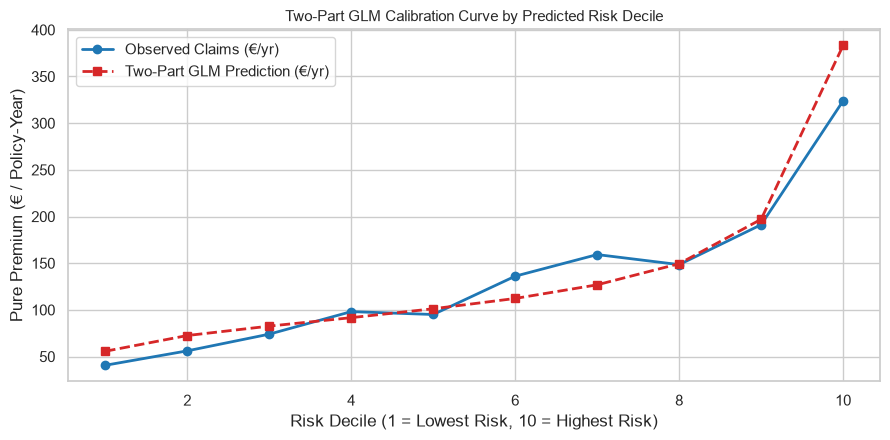

In [7]:
test_df_eval = test_df.copy()
test_df_eval["Pred_TwoPart_GLM"] = test_twopart_pure_prem_bal
calib_df = compute_calibration_table(
    test_df_eval,
    pred_col="Pred_TwoPart_GLM",
    target_loss_col="AttritionalClaimAmount",
    exposure_col="Exposure_Capped",
    n_deciles=K
)
rmsce_val = compute_rmsce(calib_df)
print(f"=== Two-Part GLM Decile Calibration Table (RMSCE: €{rmsce_val:.2f}) ===")
display(calib_df)

plt.figure(figsize=(9, 4.5))
plt.plot(calib_df["Decile"], calib_df["Observed_Pure_Premium"], marker="o", label="Observed Claims (€/yr)", color="#1f77b4", lw=2)
plt.plot(calib_df["Decile"], calib_df["Predicted_Pure_Premium"], marker="s", label="Two-Part GLM Prediction (€/yr)", color="#d62728", lw=2, linestyle="--")
plt.title("Two-Part GLM Calibration Curve by Predicted Risk Decile", fontsize=11)
plt.xlabel("Risk Decile (1 = Lowest Risk, 10 = Highest Risk)")
plt.ylabel("Pure Premium (€ / Policy-Year)")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# Save fitted GLMs + test predictions for notebooks 04-06 (each model is trained exactly once)
mpaths = {k: ("../" + v if isinstance(v, str) else v)
          for k, v in config["data"]["paths"].items()}  # config paths are project-relative; notebooks run from notebooks/
Path(mpaths["models_dir"]).mkdir(parents=True, exist_ok=True)
freq_glm.results.save(mpaths["glm_freq_results"])
sev_glm.results.save(mpaths["glm_sev_results"])
tweedie_glm.results.save(mpaths["glm_tweedie_results"])
pd.DataFrame({
    "IDpol": test_df["IDpol"].values,
    "Pred_GLM_Freq": freq_glm.predict(test_df, offset_col="LogExposure"),
    "Pred_GLM_Sev": sev_glm.predict(test_df),
    "Pred_GLM_Pure": test_twopart_pure_prem,
    "Pred_GLM_Pure_Bal": test_twopart_pure_prem_bal,
    "Pred_GLM_Tweedie_Bal": test_tweedie_pure_prem_bal,
    "Pred_GLM_Tweedie": test_tweedie_pure_prem,
}).to_parquet(mpaths["pred_glm_file"], index=False)
import json as _json
_json.dump({"glm_twopart": bal_glm, "glm_tweedie": bal_glm_tw}, open(mpaths["balance_factors_file"], "w"), indent=1)
print(f"Saved GLM results + predictions to {mpaths['models_dir']}/ and {mpaths['pred_glm_file']}")

Saved GLM results + predictions to ../models/ and ../data/processed/pred_glm.parquet
